# Controle de Acesso por Reconhecimento de Imagem: Gatos Autorizados, Cachorros Negados

Adaptação da atividade de reconhecimento facial para o dataset **gatos x cachorros** que está em `data/raw/`.

| Requisito da atividade | Como foi adaptado aqui |
|---|---|
| Bibliotecas **OpenCV** e **DeepFace** | OpenCV para leitura, detecção de rosto de gato e desenho; DeepFace para extrair os *embeddings* |
| Pasta com fotos de pessoas autorizadas | Fotos de **gatos** em `data/raw/train` (galeria de autorizados) |
| Pasta com fotos de teste | `data/raw/test` (gatos e cachorros) |
| Bounding box **verde** com "ACESSO LIBERADO" | Gato reconhecido como autorizado |
| Bounding box **vermelha** com "ACESSO NEGADO" | Cachorro (qualquer imagem que não pareça ser da galeria) |

**Como funciona:**
1. Cada imagem da galeria vira um vetor (*embedding*) via DeepFace.
2. Uma imagem nova é comparada com a galeria por similaridade de cosseno.
3. Se a similaridade ficar acima de um **limiar**, o acesso é liberado.
4. O limiar é calibrado só com dados de **treino** (um pedaço separado), sem olhar o conjunto de teste.

# Imports

In [4]:
# Instalação (descomente se necessário). O tf-keras é exigido pelo DeepFace quando o TensorFlow usa Keras 3.
# %pip install deepface tf-keras opencv-python matplotlib

import os
import re
import random
import pickle
from pathlib import Path

# Operações numéricas e visualização
import numpy as np
import matplotlib.pyplot as plt

# OpenCV: leitura, detecção e desenho das bounding boxes
import cv2

# DeepFace: extração dos embeddings
from deepface import DeepFace

# Barra de progresso
from tqdm.auto import tqdm


26-10-28 18:12:52 - Directory C:\Users\pedro\.deepface has been created
26-10-28 18:12:52 - Directory C:\Users\pedro\.deepface\weights has been created


# Configurações e Estrutura de Pastas

In [5]:
def encontrar_raiz_projeto():
    # Sobe a partir da pasta atual até achar uma pasta que contenha data/raw
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / "data" / "raw").is_dir():
            return pasta
    raise FileNotFoundError("Não encontrei data/raw. Abra o notebook dentro do projeto.")


RAIZ = encontrar_raiz_projeto()

# Entradas (já divididas em treino e teste)
DIR_TREINO = RAIZ / "data" / "raw" / "train"   # galeria de autorizados (gatos)
DIR_TESTE = RAIZ / "data" / "raw" / "test"     # imagens de teste (gatos e cachorros)

# Saídas
DIR_PROCESSED = RAIZ / "data" / "processed"                 # cache dos embeddings
DIR_RESULTADOS = RAIZ / "reports" / "figures" / "acesso_gatos"  # imagens com bounding box
for pasta in [DIR_PROCESSED, DIR_RESULTADOS / "liberado", DIR_RESULTADOS / "negado"]:
    pasta.mkdir(parents=True, exist_ok=True)

# Parâmetros
CLASSE_AUTORIZADA = "gato"
MODELO = "Facenet512"          # outras opções: "VGG-Face", "ArcFace", "Facenet"
SEED = 42
MAX_GALERIA = 300              # nº máximo de gatos na galeria de autorizados
MAX_VALIDACAO_POR_CLASSE = 100  # imagens de treino separadas para calibrar o limiar
MAX_TESTE_POR_CLASSE = 100     # use None para testar todas as imagens
TOP_K = 5                      # similaridade = média dos K gatos mais parecidos da galeria

random.seed(SEED)
np.random.seed(SEED)

print("Raiz do projeto:", RAIZ)
print("Treino:", DIR_TREINO)
print("Teste :", DIR_TESTE)

Raiz do projeto: C:\Users\pedro\Documents\GitHub\Machine_Learning_2026-2\curso_ml_cimatec\cpvisionml
Treino: C:\Users\pedro\Documents\GitHub\Machine_Learning_2026-2\curso_ml_cimatec\cpvisionml\data\raw\train
Teste : C:\Users\pedro\Documents\GitHub\Machine_Learning_2026-2\curso_ml_cimatec\cpvisionml\data\raw\test


# Listar as Imagens e Identificar a Classe

A classe de cada imagem é descoberta pelo **nome da pasta ou do arquivo** (por exemplo `train/cats/...`, `train/dog/...` ou `cat.123.jpg`). Isso funciona tanto com subpastas por classe quanto com a classe no nome do arquivo.

In [6]:
EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

PALAVRAS_CLASSE = {
    "gato": {"cat", "cats", "gato", "gatos"},
    "cachorro": {"dog", "dogs", "cachorro", "cachorros", "cao", "cão", "caes", "cães"},
}


def inferir_classe(caminho, base):
    # Junta as partes do caminho (pastas + nome do arquivo) e procura as palavras-chave
    partes = caminho.relative_to(base).with_suffix("").parts
    tokens = set(re.findall(r"[^\W\d_]+", " ".join(partes).lower()))
    achadas = [c for c, palavras in PALAVRAS_CLASSE.items() if tokens & palavras]
    return achadas[0] if len(achadas) == 1 else None


def listar_imagens(base):
    itens, ignoradas = [], []
    for p in sorted(base.rglob("*")):
        if p.is_file() and p.suffix.lower() in EXTENSOES:
            classe = inferir_classe(p, base)
            if classe:
                itens.append((p, classe))
            else:
                ignoradas.append(p)
    return itens, ignoradas


treino, ign_treino = listar_imagens(DIR_TREINO)
teste, ign_teste = listar_imagens(DIR_TESTE)

for nome, itens, ign in [("treino", treino, ign_treino), ("teste", teste, ign_teste)]:
    contagem = {c: sum(1 for _, k in itens if k == c) for c in PALAVRAS_CLASSE}
    print(f"{nome:7s}: {contagem} | sem classe identificada: {len(ign)}")
    if ign:
        print("   exemplo ignorado:", ign[0])

assert treino and teste, "Nenhuma imagem encontrada. Verifique a estrutura de data/raw."

treino : {'gato': 455, 'cachorro': 545} | sem classe identificada: 0
teste  : {'gato': 200, 'cachorro': 200} | sem classe identificada: 0


# Visualizar Algumas Imagens do Treino

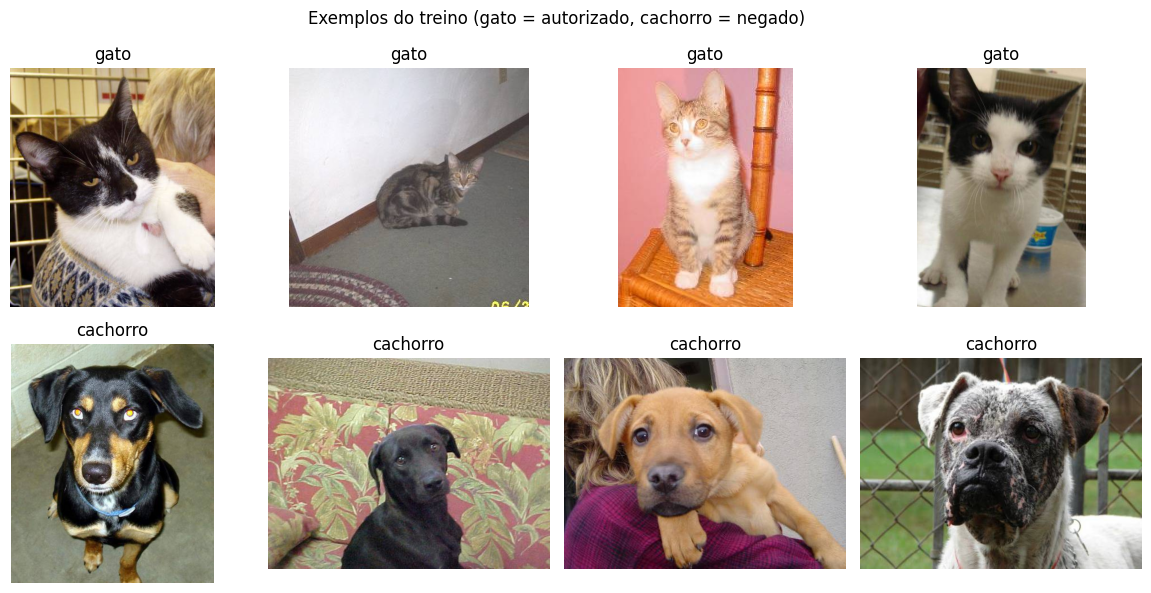

In [7]:
def ler_rgb(caminho):
    img = cv2.imread(str(caminho))
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


amostra = []
for classe in PALAVRAS_CLASSE:
    pool = [p for p, c in treino if c == classe]
    amostra += [(p, classe) for p in random.sample(pool, min(4, len(pool)))]

plt.figure(figsize=(12, 6))
for i, (p, classe) in enumerate(amostra):
    plt.subplot(2, 4, i + 1)
    plt.imshow(ler_rgb(p))
    plt.title(classe)
    plt.axis("off")
plt.suptitle("Exemplos do treino (gato = autorizado, cachorro = negado)")
plt.tight_layout()
plt.show()

# Extração dos Embeddings com DeepFace

O DeepFace foi treinado com rostos humanos. Aqui ele é usado como **extrator de características**:

- `detector_backend="skip"`: os detectores de rosto humano não encontram rostos de gatos, então a imagem inteira vai direto para a rede.
- `enforce_detection=False`: evita o erro "Face could not be detected".
- Os vetores são normalizados (norma 1), então o produto escalar equivale à similaridade de cosseno.
- Os embeddings ficam em cache em `data/processed/`, e a segunda execução fica bem mais rápida.

In [8]:
ARQ_CACHE = DIR_PROCESSED / f"embeddings_{MODELO.lower()}.pkl"
cache = pickle.load(open(ARQ_CACHE, "rb")) if ARQ_CACHE.exists() else {}


def salvar_cache():
    with open(ARQ_CACHE, "wb") as f:
        pickle.dump(cache, f)


def extrair_embedding(caminho):
    chave = str(caminho)
    if chave in cache:
        return cache[chave]

    img_bgr = cv2.imread(str(caminho))   # o DeepFace espera arrays em BGR (padrão do OpenCV)
    if img_bgr is None:
        return None

    rep = DeepFace.represent(
        img_path=img_bgr,
        model_name=MODELO,
        detector_backend="skip",
        enforce_detection=False,
        align=False,
    )
    vetor = np.asarray(rep[0]["embedding"], dtype=np.float32)
    vetor /= (np.linalg.norm(vetor) + 1e-12)
    cache[chave] = vetor
    return vetor


def embeddings_em_lote(caminhos, descricao):
    vetores, validos = [], []
    for p in tqdm(caminhos, desc=descricao):
        v = extrair_embedding(p)
        if v is not None:
            vetores.append(v)
            validos.append(p)
    salvar_cache()
    return np.stack(vetores), validos

# Galeria de Autorizados e Conjunto de Calibração

Só com imagens da pasta **train**:

- **Galeria**: gatos que serão os "autorizados".
- **Validação**: outros gatos (não usados na galeria) + cachorros, usados apenas para escolher o limiar.

In [9]:
rng = random.Random(SEED)

gatos_treino = [p for p, c in treino if c == CLASSE_AUTORIZADA]
outros_treino = [p for p, c in treino if c != CLASSE_AUTORIZADA]
rng.shuffle(gatos_treino)
rng.shuffle(outros_treino)

n_val = min(MAX_VALIDACAO_POR_CLASSE, int(0.2 * len(gatos_treino)), len(outros_treino))
n_val = max(n_val, 1)

val_autorizados = gatos_treino[:n_val]
galeria_paths = gatos_treino[n_val:n_val + MAX_GALERIA]
val_negados = outros_treino[:n_val]

print(f"Galeria de autorizados: {len(galeria_paths)} gatos")
print(f"Validação: {len(val_autorizados)} gatos + {len(val_negados)} cachorros")

GALERIA_EMB, galeria_paths = embeddings_em_lote(galeria_paths, "Galeria")
VAL_AUT_EMB, _ = embeddings_em_lote(val_autorizados, "Validação (gatos)")
VAL_NEG_EMB, _ = embeddings_em_lote(val_negados, "Validação (cachorros)")

Galeria de autorizados: 300 gatos
Validação: 91 gatos + 91 cachorros


Galeria:   0%|          | 0/300 [00:00<?, ?it/s]

26-10-28 18:13:02 - 🔗 facenet512_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facenet512_weights.h5 to C:\Users\pedro\.deepface\weights\facenet512_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facenet512_weights.h5
To: C:\Users\pedro\.deepface\weights\facenet512_weights.h5
100%|██████████| 95.0M/95.0M [00:06<00:00, 14.0MB/s]
Validação (cachorros): 100%|██████████| 91/91 [00:30<00:00,  2.96it/s]


# Pontuação de Similaridade e Limiar de Decisão

A pontuação de uma imagem é a **média das `TOP_K` maiores similaridades** com a galeria. O limiar é o valor que maximiza a **acurácia balanceada** na validação.

Limiar escolhido: 0.8726  (acurácia balanceada na validação: 0.549)


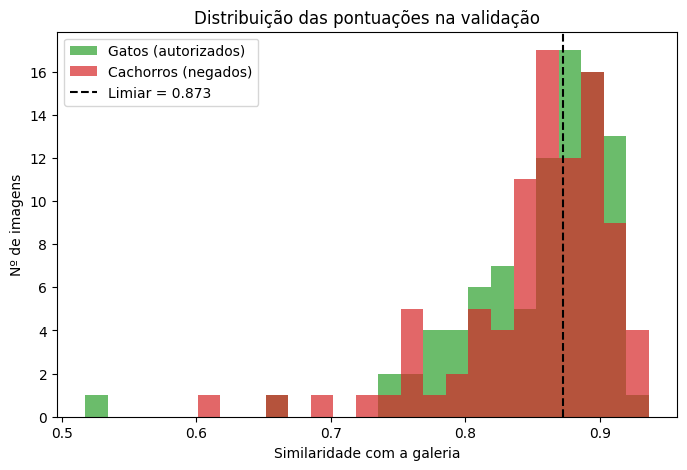

In [10]:
def pontuar_lote(embs, galeria=None, k=TOP_K):
    galeria = GALERIA_EMB if galeria is None else galeria
    sims = embs @ galeria.T                  # (n_imagens, n_galeria)
    k = min(k, sims.shape[1])
    return np.sort(sims, axis=1)[:, -k:].mean(axis=1)


def escolher_limiar(scores_pos, scores_neg):
    scores = np.concatenate([scores_pos, scores_neg])
    y = np.concatenate([np.ones(len(scores_pos), bool), np.zeros(len(scores_neg), bool)])
    melhor_t, melhor_bal = None, -1
    for t in np.unique(scores):
        pred = scores >= t
        tpr = (pred & y).sum() / y.sum()
        tnr = (~pred & ~y).sum() / (~y).sum()
        bal = (tpr + tnr) / 2
        if bal > melhor_bal:
            melhor_t, melhor_bal = float(t), float(bal)
    return melhor_t, melhor_bal


scores_val_aut = pontuar_lote(VAL_AUT_EMB)
scores_val_neg = pontuar_lote(VAL_NEG_EMB)
LIMIAR, bal_val = escolher_limiar(scores_val_aut, scores_val_neg)

print(f"Limiar escolhido: {LIMIAR:.4f}  (acurácia balanceada na validação: {bal_val:.3f})")

plt.figure(figsize=(8, 5))
todos = np.concatenate([scores_val_aut, scores_val_neg])
faixas = np.linspace(todos.min() - 1e-3, todos.max() + 1e-3, 26)
plt.hist(scores_val_aut, bins=faixas, alpha=0.7, label="Gatos (autorizados)", color="tab:green")
plt.hist(scores_val_neg, bins=faixas, alpha=0.7, label="Cachorros (negados)", color="tab:red")
plt.axvline(LIMIAR, color="k", linestyle="--", label=f"Limiar = {LIMIAR:.3f}")
plt.title("Distribuição das pontuações na validação")
plt.xlabel("Similaridade com a galeria")
plt.ylabel("Nº de imagens")
plt.legend()
plt.show()

# Bounding Box com OpenCV

- O OpenCV já traz o classificador Haar `haarcascade_frontalcatface_extended.xml` para **rostos de gato**. Se ele encontrar um rosto, a caixa é desenhada nele.
- Se não encontrar (caso comum em cachorros e fotos difíceis), a caixa cobre a **imagem inteira**, com uma pequena margem.
- A cor e o texto dependem só da decisão do DeepFace: **verde + "ACESSO LIBERADO"** ou **vermelho + "ACESSO NEGADO"**.

In [12]:
COR_VERDE = (0, 200, 0)      # BGR
COR_VERMELHO = (0, 0, 255)   # BGR
COR_TEXTO = (255, 255, 255)
FONTE = cv2.FONT_HERSHEY_SIMPLEX

NOME_CASCADE = "haarcascade_frontalcatface_extended.xml"
URL_CASCADE = ("https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/"
               + NOME_CASCADE)


def carregar_detector_gato():
    # 1) Tenta os arquivos que acompanham o OpenCV e uma cópia local em data/external
    pasta_cv = Path(cv2.data.haarcascades)
    candidatos = [
        pasta_cv / NOME_CASCADE,
        pasta_cv / "haarcascade_frontalcatface.xml",
        RAIZ / "data" / "external" / NOME_CASCADE,
    ]
    for c in candidatos:
        if c.exists():
            det = cv2.CascadeClassifier(str(c))
            if not det.empty():
                print("Classificador de rosto de gato carregado:", c)
                return det

    # 2) Se não achou, baixa o XML oficial do OpenCV para data/external
    destino = RAIZ / "data" / "external" / NOME_CASCADE
    try:
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URL_CASCADE, destino)
        det = cv2.CascadeClassifier(str(destino))
        if not det.empty():
            print("Classificador baixado e carregado:", destino)
            return det
    except Exception as erro:
        print("Falha ao baixar o classificador:", erro)

    # 3) Último recurso: segue sem detector (a caixa cobrirá a imagem inteira)
    print("AVISO: classificador indisponível. A bounding box cobrirá a imagem inteira.")
    return None


detector_gato = carregar_detector_gato()


def localizar_caixa(img_bgr):
    alt, larg = img_bgr.shape[:2]

    if detector_gato is not None:
        cinza = cv2.equalizeHist(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY))
        rostos = detector_gato.detectMultiScale(
            cinza, scaleFactor=1.05, minNeighbors=3, minSize=(40, 40)
        )
        if len(rostos) > 0:
            x, y, w, h = max(rostos, key=lambda r: r[2] * r[3])   # maior rosto
            return (int(x), int(y), int(w), int(h)), True

    m = int(0.03 * min(alt, larg))
    return (m, m, larg - 2 * m, alt - 2 * m), False


def desenhar_resultado(img_bgr, caixa, liberado):
    img = img_bgr.copy()
    cor = COR_VERDE if liberado else COR_VERMELHO
    texto = "ACESSO LIBERADO" if liberado else "ACESSO NEGADO"

    x, y, w, h = caixa
    alt, larg = img.shape[:2]
    espessura = max(2, int(round(min(alt, larg) / 150)))
    escala = max(0.5, larg / 600)

    cv2.rectangle(img, (x, y), (x + w, y + h), cor, espessura)

    (tw, th), base = cv2.getTextSize(texto, FONTE, escala, espessura)
    y_topo = y - th - base - espessura          # tenta colocar o texto acima da caixa
    if y_topo < 0:                              # se não couber, coloca dentro
        y_topo = y + espessura
    x_txt = min(x, max(0, larg - tw - 2 * espessura))

    cv2.rectangle(img, (x_txt, y_topo),
                  (x_txt + tw + 2 * espessura, y_topo + th + base + espessura), cor, -1)
    cv2.putText(img, texto, (x_txt + espessura, y_topo + th + espessura // 2),
                FONTE, escala, COR_TEXTO, espessura, cv2.LINE_AA)
    return img

Falha ao baixar o classificador: name 'urllib' is not defined
AVISO: classificador indisponível. A bounding box cobrirá a imagem inteira.


# Função de Verificação de Acesso

In [13]:
def verificar_acesso(caminho, salvar_em=None):
    img = cv2.imread(str(caminho))
    if img is None:
        raise ValueError(f"Não consegui abrir a imagem: {caminho}")

    emb = extrair_embedding(caminho)
    score = float(pontuar_lote(emb[None, :])[0])
    liberado = score >= LIMIAR

    caixa, achou_rosto = localizar_caixa(img)
    img_resultado = desenhar_resultado(img, caixa, liberado)

    if salvar_em is not None:
        cv2.imwrite(str(salvar_em), img_resultado)

    return {
        "caminho": Path(caminho),
        "score": score,
        "liberado": liberado,
        "rosto_detectado": achou_rosto,
        "imagem": img_resultado,
    }

# Executar no Conjunto de Teste (`data/raw/test`)

As imagens anotadas são salvas em `reports/figures/acesso_gatos/liberado` e `.../negado`.

In [14]:
rng_teste = random.Random(SEED)
teste_selecionado = []
for classe in PALAVRAS_CLASSE:
    pool = [(p, c) for p, c in teste if c == classe]
    rng_teste.shuffle(pool)
    teste_selecionado += pool if MAX_TESTE_POR_CLASSE is None else pool[:MAX_TESTE_POR_CLASSE]

resultados = []
for p, classe_real in tqdm(teste_selecionado, desc="Teste"):
    r = verificar_acesso(p)
    pasta = "liberado" if r["liberado"] else "negado"
    destino = DIR_RESULTADOS / pasta / f"{classe_real}_{p.stem}.jpg"
    cv2.imwrite(str(destino), r["imagem"])

    r["classe_real"] = classe_real
    r["arquivo_saida"] = destino
    del r["imagem"]   # a imagem anotada já está salva em disco
    resultados.append(r)

salvar_cache()
print(f"{len(resultados)} imagens de teste processadas.")
print("Anotadas salvas em:", DIR_RESULTADOS)

Teste: 100%|██████████| 200/200 [01:08<00:00,  2.92it/s]

200 imagens de teste processadas.
Anotadas salvas em: C:\Users\pedro\Documents\GitHub\Machine_Learning_2026-2\curso_ml_cimatec\cpvisionml\reports\figures\acesso_gatos


# Métricas

Acurácia : 0.530
Precisão : 0.535  (dos liberados, quantos eram gatos)
Recall   : 0.460  (dos gatos, quantos foram liberados)
FAR      : 0.400  (cachorros liberados por engano)
FRR      : 0.540  (gatos negados por engano)


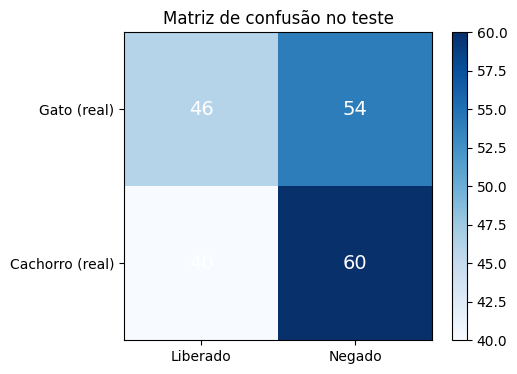

In [15]:
y_real = np.array([r["classe_real"] == CLASSE_AUTORIZADA for r in resultados])
y_pred = np.array([r["liberado"] for r in resultados])

vp = int((y_pred & y_real).sum())     # gato liberado
fn = int((~y_pred & y_real).sum())    # gato negado
fp = int((y_pred & ~y_real).sum())    # cachorro liberado (o erro mais grave)
vn = int((~y_pred & ~y_real).sum())   # cachorro negado

acuracia = (vp + vn) / len(resultados)
precisao = vp / (vp + fp) if (vp + fp) else 0.0
recall = vp / (vp + fn) if (vp + fn) else 0.0
far = fp / (fp + vn) if (fp + vn) else 0.0   # False Acceptance Rate
frr = fn / (fn + vp) if (fn + vp) else 0.0   # False Rejection Rate

print(f"Acurácia : {acuracia:.3f}")
print(f"Precisão : {precisao:.3f}  (dos liberados, quantos eram gatos)")
print(f"Recall   : {recall:.3f}  (dos gatos, quantos foram liberados)")
print(f"FAR      : {far:.3f}  (cachorros liberados por engano)")
print(f"FRR      : {frr:.3f}  (gatos negados por engano)")

matriz = np.array([[vp, fn], [fp, vn]])
plt.figure(figsize=(5, 4))
plt.imshow(matriz, cmap="Blues")
plt.xticks([0, 1], ["Liberado", "Negado"])
plt.yticks([0, 1], ["Gato (real)", "Cachorro (real)"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz[i, j], ha="center", va="center", fontsize=14,
                 color="white" if matriz[i, j] > matriz.max() / 2 else "black")
plt.title("Matriz de confusão no teste")
plt.colorbar()
plt.show()

# Visualizar os Resultados com as Bounding Boxes

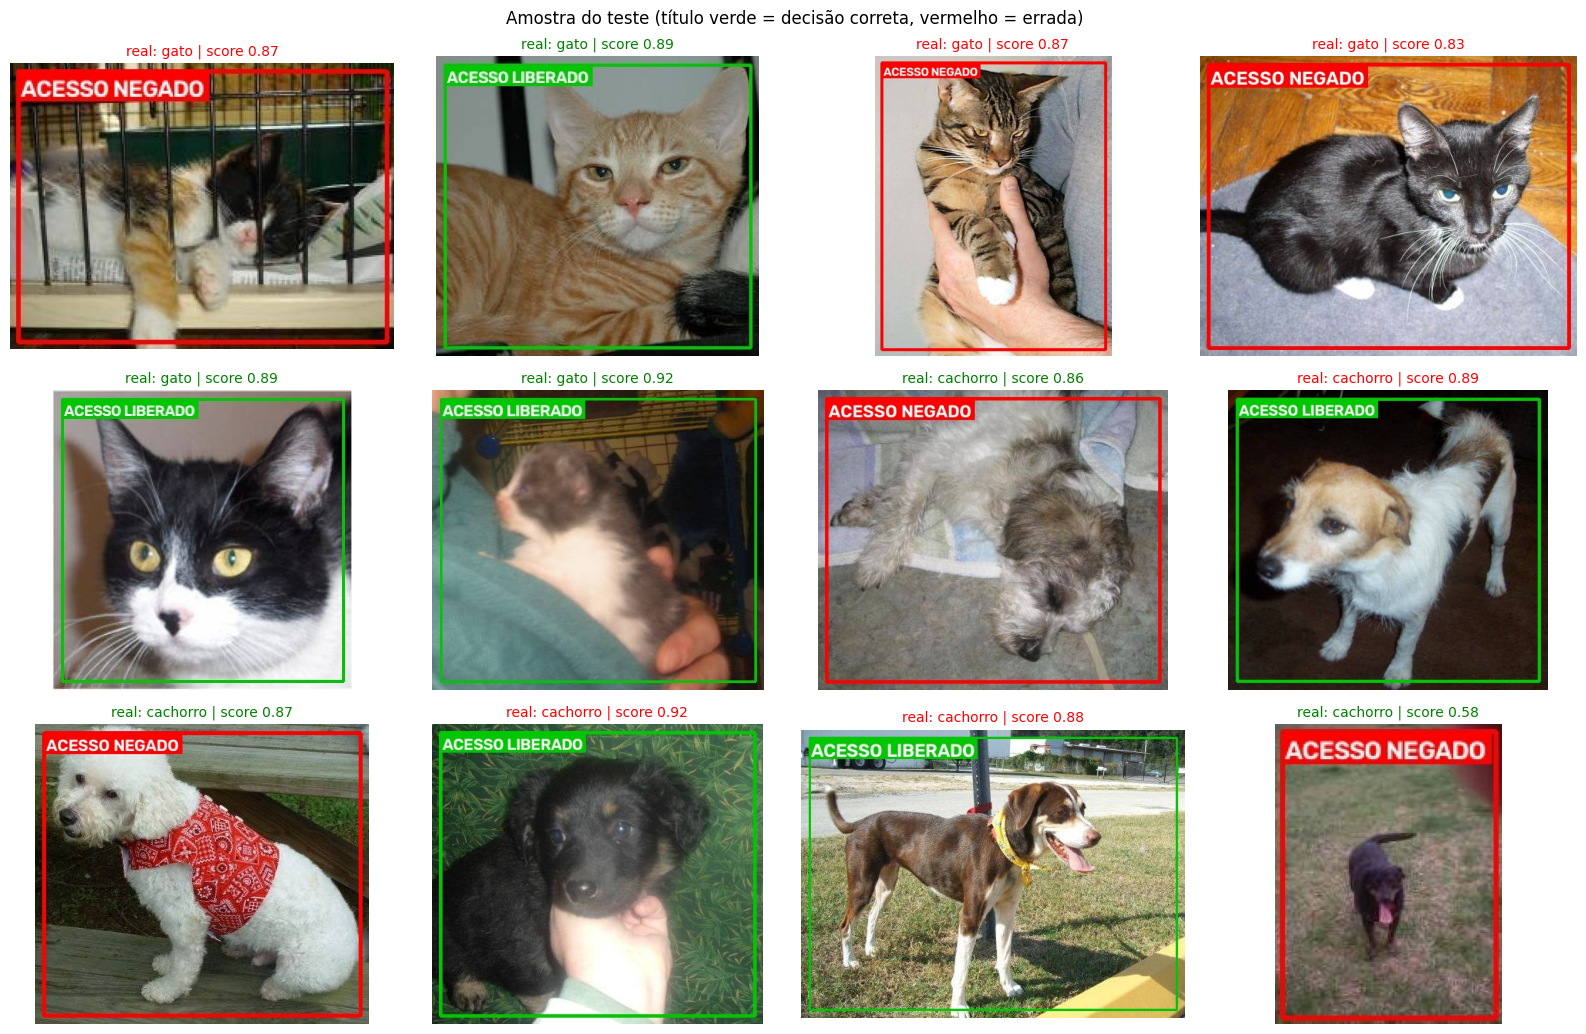

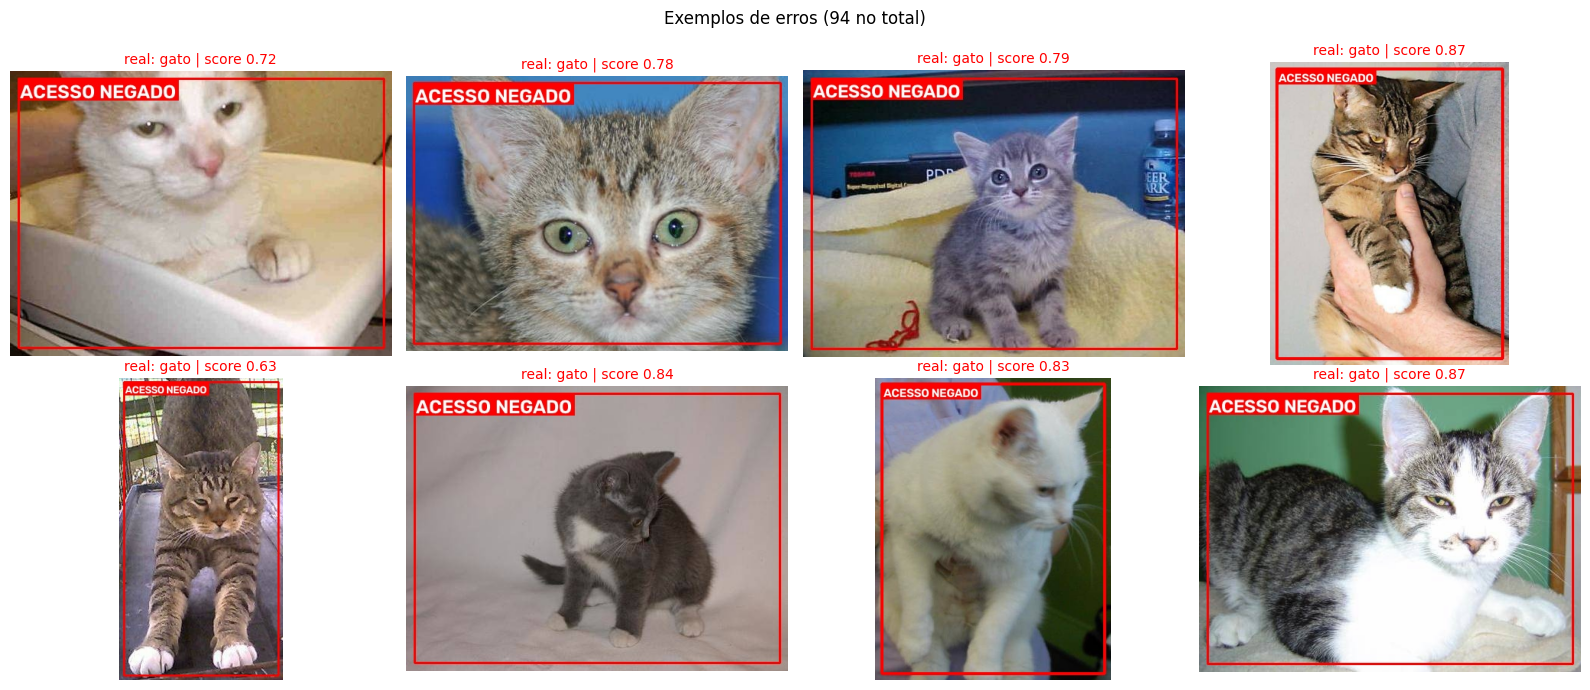

In [16]:
def mostrar_grade(lista, titulo, colunas=4):
    if not lista:
        print("Nada para mostrar em:", titulo)
        return
    linhas = int(np.ceil(len(lista) / colunas))
    plt.figure(figsize=(4 * colunas, 3.5 * linhas))
    for i, r in enumerate(lista):
        plt.subplot(linhas, colunas, i + 1)
        plt.imshow(ler_rgb(r["arquivo_saida"]))
        certo = r["liberado"] == (r["classe_real"] == CLASSE_AUTORIZADA)
        plt.title(f"real: {r['classe_real']} | score {r['score']:.2f}",
                  color="green" if certo else "red", fontsize=10)
        plt.axis("off")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


rng_viz = random.Random(SEED)
gatos_res = [r for r in resultados if r["classe_real"] == "gato"]
caes_res = [r for r in resultados if r["classe_real"] != "gato"]
amostra_viz = rng_viz.sample(gatos_res, min(6, len(gatos_res))) + \
              rng_viz.sample(caes_res, min(6, len(caes_res)))

mostrar_grade(amostra_viz, "Amostra do teste (título verde = decisão correta, vermelho = errada)")

erros = [r for r in resultados
         if r["liberado"] != (r["classe_real"] == CLASSE_AUTORIZADA)]
mostrar_grade(erros[:8], f"Exemplos de erros ({len(erros)} no total)")

# Testar uma Imagem Avulsa

Imagem        : cat.9879.jpg
Pontuação     : 0.7178 | limiar: 0.8726
Rosto detectado pelo OpenCV: False
Decisão       : ACESSO NEGADO


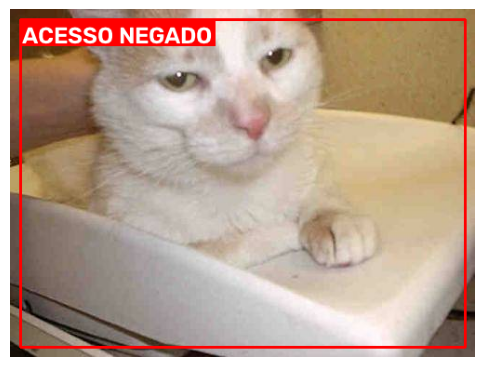

In [17]:
# Troque pelo caminho de qualquer imagem
CAMINHO_IMAGEM = teste_selecionado[0][0]

r = verificar_acesso(CAMINHO_IMAGEM)
print("Imagem        :", r["caminho"].name)
print("Pontuação     :", round(r["score"], 4), "| limiar:", round(LIMIAR, 4))
print("Rosto detectado pelo OpenCV:", r["rosto_detectado"])
print("Decisão       :", "ACESSO LIBERADO" if r["liberado"] else "ACESSO NEGADO")

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(r["imagem"], cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# Observações

- **DeepFace e gatos:** os modelos do DeepFace foram treinados para rostos humanos. Aqui eles funcionam como extratores genéricos de características, e a qualidade da separação gato x cachorro é limitada. O histograma da validação mostra o quanto as duas classes se separam.
- **Se a acurácia ficar baixa**, experimente `MODELO = "VGG-Face"` ou `"ArcFace"`, aumente `MAX_GALERIA` ou ajuste `TOP_K`. A CNN do notebook anterior, treinada com gatos e cachorros, tende a separar melhor as classes.
- **Erro mais grave:** em controle de acesso o pior erro é liberar quem não deveria (FAR). Para ser mais restritivo, aumente `LIMIAR` manualmente.
- **Bounding box:** o OpenCV só localiza rostos de gato (frontais). Quando não encontra, a caixa cobre a imagem toda.